In [1]:
import pandas as pd
ratings_df = pd.read_csv('../data/raw/ratings.csv',nrows=2_000_000)
display(ratings_df.head(10))
print("number of NaN values:", ratings_df.isna().sum().sum())
print("number of unique users:", ratings_df['userId'].nunique())
print("number of unique movies:", ratings_df['movieId'].nunique())
print("number of ratings:", ratings_df.shape[0])

,userId,movieId,rating,timestamp
0,1,2,3.5,1112486027
1,1,29,3.5,1112484676
2,1,32,3.5,1112484819
3,1,47,3.5,1112484727
4,1,50,3.5,1112484580
5,1,112,3.5,1094785740
6,1,151,4.0,1094785734
7,1,223,4.0,1112485573
8,1,253,4.0,1112484940
9,1,260,4.0,1112484826


number of NaN values: 0
number of unique users: 13567
number of unique movies: 16715
number of ratings: 2000000


<Axes: title={'center': 'number of ratings per year'}, xlabel='year'>

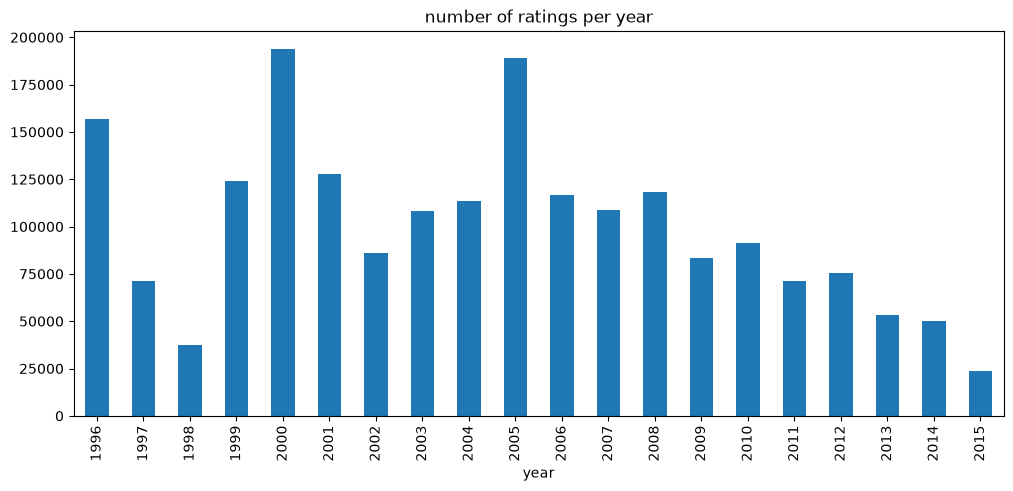

In [2]:
ratings_df['timestamp']= pd.to_datetime(ratings_df['timestamp'], unit='s')
ratings_df.head()
ratings_df['year'] = ratings_df['timestamp'].dt.year
ratings_df.groupby('year')['rating'].count().plot(kind='bar', figsize=(12, 5), title='number of ratings per year')


Text(0, 0.5, 'number of users for each bin of ratings')

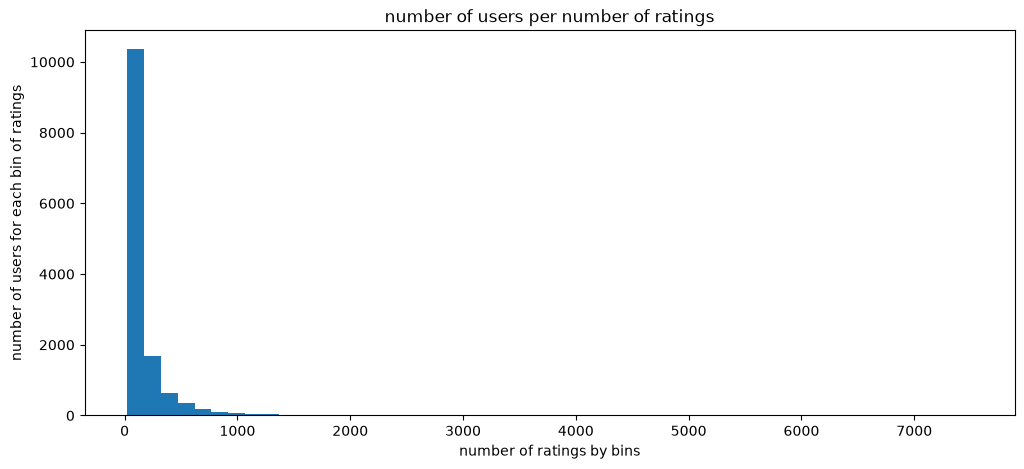

In [3]:
import matplotlib.pyplot as plt
ratings_df['userId'].value_counts().plot(kind='hist', y='rating', bins=50, figsize=(12, 5), title='number of users per number of ratings')
plt.xlabel('number of ratings by bins')
plt.ylabel('number of users for each bin of ratings')

In [4]:
ratings_df.to_parquet('../data/processed/ratings_df.parquet')